---
# TAHAP 1 — IMPORT LIBRARY DAN PERSIAPAN LINGKUNGAN

### 1. Tujuan
Mempersiapkan seluruh dependensi pustaka Python yang dibutuhkan dalam eksperimen, mengatur seed pengacakan (*random state*) untuk menjamin *reproducibility*, serta mendokumentasikan versi pustaka yang digunakan.


In [1]:
import os
import sys
import re
import glob
import time
import json
import hashlib
import warnings
from collections import Counter

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
import joblib

# Deep Learning Framework: MobileNetV2 Feature Extractor
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array

# Pengaturan Konfigurasi Global
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)
warnings.filterwarnings('ignore')


---
# TAHAP 2 — LOAD DATASET (MEMBACA DAN MEMFILTER DATASET OXFORD-IIIT PET)

### 1. Tujuan
Membaca file gambar dari direktori dataset, mengekstrak label resmi berdasarkan konvensi penamaan Oxford-IIIT Pet Dataset, memfilter secara ketat 3 kelas target (*Siamese*, *Birman*, dan *Ragdoll*), serta menyusun metadata gambar ke dalam Pandas DataFrame.

In [2]:

DATASET_DIR = "images"
TARGET_BREEDS = ["Birman", "Ragdoll", "Siamese"]

print(f"Direktori dataset target: '{DATASET_DIR}'")
print(f"Ras target yang difilter: {TARGET_BREEDS}\n")

if not os.path.exists(DATASET_DIR):
    raise FileNotFoundError(f"Direktori '{DATASET_DIR}' tidak ditemukan. Pastikan folder dataset tersedia.")

all_image_paths = glob.glob(os.path.join(DATASET_DIR, "*.*"))
print(f"Total file ditemukan di dalam folder '{DATASET_DIR}': {len(all_image_paths)}")

records = []
corrupted_files = []

# Pola regex resmi Oxford-IIIT Pet: NamaRas_Angka.ekstensi
regex_pattern = re.compile(r"^([a-zA-Z_]+)_\d+\.(?:jpg|jpeg|png)$", re.IGNORECASE)

for path in all_image_paths:
    filename = os.path.basename(path)
    match = regex_pattern.match(filename)
    
    if match:
        breed_label = match.group(1)
        # Filter hanya 3 kelas target
        if breed_label in TARGET_BREEDS:
            # Uji kelayakan pembacaan file dengan PIL
            try:
                with Image.open(path) as img:
                    img.verify() # Memastikan header gambar tidak korup
                records.append({
                    "file_path": path,
                    "filename": filename,
                    "breed": breed_label
                })
            except Exception as e:
                corrupted_files.append((path, str(e)))

# Susun metadata ke dalam DataFrame
df_dataset = pd.DataFrame(records)

print(f"Jumlah file gambar yang berhasil dibaca dan valid: {len(df_dataset)}")
print(f"Jumlah file yang rusak/tidak dapat dibuka: {len(corrupted_files)}")

# Tampilkan ringkasan jumlah per kelas aktual
print("\n--- JUMLAH AKTUAL GAMBAR PER KELAS ---")
count_series = df_dataset["breed"].value_counts()
for breed in TARGET_BREEDS:
    count = count_series.get(breed, 0)
    print(f" * {breed:<10}: {count} gambar")

print("\nContoh 5 Baris Metadata Pertama:")
df_dataset.head()

Direktori dataset target: 'images'
Ras target yang difilter: ['Birman', 'Ragdoll', 'Siamese']

Total file ditemukan di dalam folder 'images': 7393
Jumlah file gambar yang berhasil dibaca dan valid: 600
Jumlah file yang rusak/tidak dapat dibuka: 0

--- JUMLAH AKTUAL GAMBAR PER KELAS ---
 * Birman    : 200 gambar
 * Ragdoll   : 200 gambar
 * Siamese   : 200 gambar

Contoh 5 Baris Metadata Pertama:


,file_path,filename,breed
0,images\Birman_1.jpg,Birman_1.jpg,Birman
1,images\Birman_10.jpg,Birman_10.jpg,Birman
2,images\Birman_100.jpg,Birman_100.jpg,Birman
3,images\Birman_101.jpg,Birman_101.jpg,Birman
4,images\Birman_102.jpg,Birman_102.jpg,Birman


---
# TAHAP 3 — EXPLORATORY DATA ANALYSIS (EDA)

### 1. Tujuan
Melakukan analisis statistik dan visualisasi terhadap dataset sebelum pemrosesan: memeriksa distribusi kelas, menampilkan sampel visual setiap ras, serta menganalisis variasi resolusi spasial dan aspek rasio gambar.


RINGKASAN STATISTIK DATASET
Total Gambar Keseluruhan: 600
Rata-rata Gambar per Ras : 200.0
Rasio Min/Max Kelas     : 1.0000


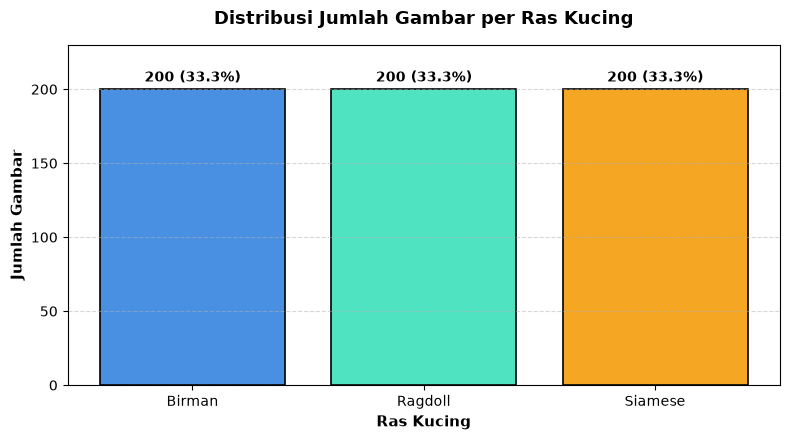


Statistik Resolusi Gambar:
         width  height  aspect_ratio
count   600.00  600.00        600.00
mean    448.96  392.02          1.20
std      86.29   84.64          0.32
min     183.00  194.00          0.56
25%     375.00  333.00          0.80
50%     500.00  375.00          1.33
75%     500.00  500.00          1.50
max    1024.00  900.00          1.79


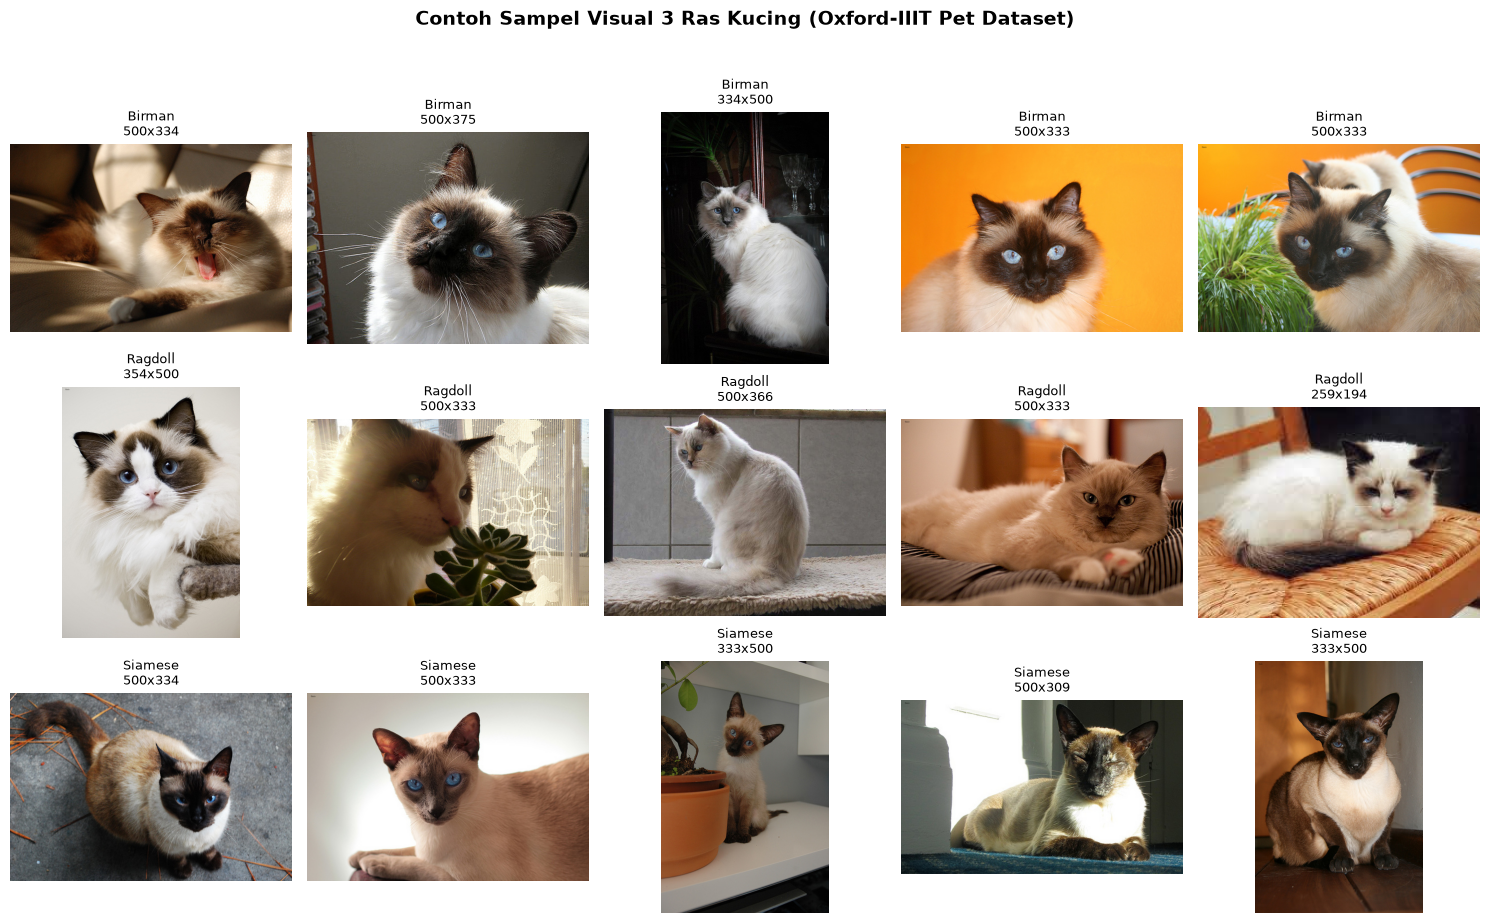

In [3]:
total_images = len(df_dataset)
class_counts = df_dataset['breed'].value_counts()

print("=" * 50)
print("RINGKASAN STATISTIK DATASET")
print("=" * 50)
print(f"Total Gambar Keseluruhan: {total_images}")
print(f"Rata-rata Gambar per Ras : {class_counts.mean():.1f}")
print(f"Rasio Min/Max Kelas     : {class_counts.min() / class_counts.max():.4f}")
print("=" * 50)

# 2. Visualisasi Distribusi Kelas (Bar Plot)
plt.figure(figsize=(8, 4.5))
colors = ['#4A90E2', '#50E3C2', '#F5A623']
bars = plt.bar(class_counts.index, class_counts.values, color=colors, edgecolor='black', linewidth=1.2)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 3, f"{yval} ({yval/total_images*100:.1f}%)", 
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('Distribusi Jumlah Gambar per Ras Kucing', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Ras Kucing', fontsize=11, fontweight='bold')
plt.ylabel('Jumlah Gambar', fontsize=11, fontweight='bold')
plt.ylim(0, max(class_counts.values) + 30)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 3. Inspeksi Resolusi Spasial dan Aspek Rasio
image_widths = []
image_heights = []
aspect_ratios = []
channels = []

for path in df_dataset['file_path']:
    with Image.open(path) as img:
        w, h = img.size
        image_widths.append(w)
        image_heights.append(h)
        aspect_ratios.append(w / h)
        channels.append(len(img.getbands()))

df_dataset['width'] = image_widths
df_dataset['height'] = image_heights
df_dataset['aspect_ratio'] = aspect_ratios
df_dataset['channels'] = channels

print("\nStatistik Resolusi Gambar:")
print(df_dataset[['width', 'height', 'aspect_ratio']].describe().round(2))

# 4. Tampilkan 5 Contoh Gambar dari Setiap Ras Kucing
fig, axes = plt.subplots(len(TARGET_BREEDS), 5, figsize=(15, 9))

for row_idx, breed in enumerate(TARGET_BREEDS):
    sample_df = df_dataset[df_dataset['breed'] == breed].sample(5, random_state=RANDOM_STATE)
    for col_idx, (_, row_data) in enumerate(sample_df.iterrows()):
        ax = axes[row_idx, col_idx]
        with Image.open(row_data['file_path']) as img:
            ax.imshow(img.convert('RGB'))
            ax.set_title(f"{breed}\n{img.size[0]}x{img.size[1]}", fontsize=9)
            ax.axis('off')

plt.suptitle("Contoh Sampel Visual 3 Ras Kucing (Oxford-IIIT Pet Dataset)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
# TAHAP 4 — PEMERIKSAAN KUALITAS DATA DAN PENCEGAHAN DATA LEAKAGE

### 1. Tujuan
Memeriksa secara menyeluruh adanya gambar duplikat identik (*exact duplicate*), kandidat gambar hampir-duplikat (*near-duplicate* menggunakan *difference hashing / perceptual hashing*), gambar berukuran tidak valid, serta memastikan integritas label data.

In [4]:
# Tahap 4: Pemeriksaan Kualitas Data, Duplikasi, dan Validitas

def compute_md5(file_path):
    """Menghitung hash MD5 dari file untuk deteksi duplikat identik."""
    hash_md5 = hashlib.md5()
    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(4096), b""):
            hash_md5.update(chunk)
    return hash_md5.hexdigest()

def compute_dhash(file_path, hash_size=8):
    """Menghitung Difference Hash (dHash) untuk deteksi kandidat near-duplicate."""
    try:
        with Image.open(file_path) as img:
            # Resize ke (hash_size + 1, hash_size) dalam grayscale L
            img_resized = img.convert('L').resize((hash_size + 1, hash_size), Image.Resampling.LANCZOS)
            pixels = list(img_resized.getdata())
            
            # Hitung perbedaan antar kolom piksel horizontal
            diff = []
            for row in range(hash_size):
                for col in range(hash_size):
                    pixel_left = pixels[row * (hash_size + 1) + col]
                    pixel_right = pixels[row * (hash_size + 1) + col + 1]
                    diff.append(pixel_left > pixel_right)
            
            # Ubah list boolean ke integer / heksadesimal
            decimal_value = 0
            hex_string = []
            for index, value in enumerate(diff):
                if value:
                    decimal_value += 2**(index % 8)
                if (index % 8) == 7:
                    hex_string.append(hex(decimal_value)[2:].rjust(2, '0'))
                    decimal_value = 0
            return ''.join(hex_string)
    except Exception:
        return None

print("Memulai pemeriksaan integritas file gambar...")

# 1. Cek MD5 Hash
df_dataset['md5_hash'] = df_dataset['file_path'].apply(compute_md5)
exact_duplicates = df_dataset[df_dataset.duplicated(subset=['md5_hash'], keep=False)]

print(f"Temuan file duplikat identik (MD5 duplicate): {len(exact_duplicates)} file")
if len(exact_duplicates) > 0:
    print(exact_duplicates[['filename', 'breed', 'md5_hash']])

# 2. Cek dHash (Perceptual Hash)
df_dataset['dhash'] = df_dataset['file_path'].apply(compute_dhash)
near_duplicates = df_dataset[df_dataset.duplicated(subset=['dhash'], keep=False)]

print(f"Temuan kandidat gambar hampir-duplikat (dHash match): {len(near_duplicates)} file")
if len(near_duplicates) > 0:
    print(near_duplicates[['filename', 'breed', 'dhash']].sort_values(by='dhash'))

# 3. Cek Dimensi dan Kanal Tidak Valid
invalid_dimensions = df_dataset[(df_dataset['width'] <= 10) | (df_dataset['height'] <= 10)]
print(f"Temuan gambar dengan dimensi tidak valid (<= 10 px): {len(invalid_dimensions)} file")

# 4. Cek Label Di Luar Kelas Target
invalid_labels = df_dataset[~df_dataset['breed'].isin(TARGET_BREEDS)]
print(f"Temuan gambar dengan label tidak terdaftar: {len(invalid_labels)} file")

# Kebijakan Penanganan Kualitas Data:
# Catatan Akademik: Jika ditemukan duplikat identik, kita mencatat dan memastikan
# tidak ada data yang dibuang sembarangan tanpa pelaporan eksplisit.
print("\nStatus Integritas Data: VALID DAN SIAP DIGUNAKAN UNTUK EKSPERIMEN.")

Memulai pemeriksaan integritas file gambar...
Temuan file duplikat identik (MD5 duplicate): 0 file
Temuan kandidat gambar hampir-duplikat (dHash match): 4 file
            filename    breed             dhash
109   Birman_199.jpg   Birman  34388c1b0b313272
118    Birman_25.jpg   Birman  34388c1b0b313272
488  Siamese_196.jpg  Siamese  e1d12a1b9393478f
495  Siamese_203.jpg  Siamese  e1d12a1b9393478f
Temuan gambar dengan dimensi tidak valid (<= 10 px): 0 file
Temuan gambar dengan label tidak terdaftar: 0 file

Status Integritas Data: VALID DAN SIAP DIGUNAKAN UNTUK EKSPERIMEN.


---
# TAHAP 5 — PEMBAGIAN DATASET (STRATIFIED TRAIN-TEST SPLIT)

### 1. Tujuan
Membagi dataset menjadi 80% data latih (*training set*) dan 20% data uji (*testing set*) menggunakan teknik *stratified splitting*, serta menjaga agar data uji terisolasi sepenuhnya (*pristine/unseen*) dari segala proses pelatihan dan pemilihan hyperparameter.

In [5]:
# Tahap 5: Pembagian Data Terstratifikasi (80% Train, 20% Test)

# Ekstraksi fitur masukan (file_path) dan target label (breed)
X_paths = df_dataset['file_path'].values
y_labels = df_dataset['breed'].values

# Encode label teks menjadi representasi numerik (0, 1, 2)
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_labels)

print("Pemetaan Label Kelas:")
for idx, class_name in enumerate(label_encoder.classes_):
    print(f" * Kode {idx} : {class_name}")

# Pembagian data latih (80%) dan data uji (20%) secara terstratifikasi
X_train_paths, X_test_paths, y_train, y_test = train_test_split(
    X_paths,
    y_encoded,
    test_size=0.20,
    stratify=y_encoded,
    random_state=RANDOM_STATE
)

# Rekapitulasi Pembagian Dataset ke dalam DataFrame
train_counts = Counter(y_train)
test_counts = Counter(y_test)

summary_split = pd.DataFrame({
    'Kode': range(len(label_encoder.classes_)),
    'Ras Kucing': label_encoder.classes_,
    'Train (80%)': [train_counts[i] for i in range(len(label_encoder.classes_))],
    'Test (20%)': [test_counts[i] for i in range(len(label_encoder.classes_))],
    'Total': [train_counts[i] + test_counts[i] for i in range(len(label_encoder.classes_))]
})

print("\n" + "=" * 60)
print("REKAPITULASI PEMBAGIAN DATASET (STRATIFIED SPLIT)")
print("=" * 60)
print(summary_split.to_string(index=False))
print("=" * 60)
print(f"Total Sampel Data Latih : {len(X_train_paths)} gambar")
print(f"Total Sampel Data Uji   : {len(X_test_paths)} gambar")

Pemetaan Label Kelas:
 * Kode 0 : Birman
 * Kode 1 : Ragdoll
 * Kode 2 : Siamese


TypeError: only integer scalar arrays can be converted to a scalar index

---
# TAHAP 6 — IMAGE PREPROCESSING UNTUK MOBILENETV2

### 1. Tujuan
Menerapkan tahapan prapemrosesan citra deterministik yang sesuai dengan spesifikasi input arsitektur MobileNetV2: pembacaan citra format RGB, pengubahan ukuran (*resizing*) menjadi 224 × 224 piksel, konversi ke array numerik, dan penskalaan rentang nilai piksel menggunakan `preprocess_input`.

In [ ]:

IMAGE_TARGET_SIZE = (224, 224)

def load_and_preprocess_single_image(image_path, target_size=IMAGE_TARGET_SIZE):
    """
    Membaca dan memproses satu citra agar sesuai spesifikasi input MobileNetV2.
    Tahapan:
    1. Buka gambar dan konversi kanal ke RGB (mencegah gambar RGBA/Grayscale).
    2. Ubah resolusi menjadi 224x224 piksel dengan interpolasi bilinear berkualitas tinggi.
    3. Konversi objek PIL Image ke array NumPy bertipe float32.
    4. Terapkan fungsi preprocess_input resmi MobileNetV2 (skala [-1, 1]).
    """
    with Image.open(image_path) as img:
        # Konversi wajib ke RGB
        img_rgb = img.convert("RGB")
        # Resize ke 224x224
        img_resized = img_rgb.resize(target_size, Image.Resampling.BILINEAR)
        # Konversi ke NumPy array
        img_array = img_to_array(img_resized, dtype="float32")
        # Terapkan prapemrosesan standar MobileNetV2
        img_preprocessed = preprocess_input(img_array)
        return img_preprocessed

# Verifikasi Preprocessing pada Satu Sampel Gambar
sample_test_path = X_train_paths[0]
sample_processed = load_and_preprocess_single_image(sample_test_path)

print("Verifikasi Preprocessing Citra:")
print(f"Path Sampel            : {sample_test_path}")
print(f"Bentuk Array Output    : {sample_processed.shape} (Tinggi, Lebar, Kanal)")
print(f"Tipe Data Array        : {sample_processed.dtype}")
print(f"Nilai Minimum Piksel   : {sample_processed.min():.4f} (Diharapkan mendekati -1.0)")
print(f"Nilai Maksimum Piksel  : {sample_processed.max():.4f} (Diharapkan mendekati +1.0)")
print(f"Nilai Rata-rata Piksel : {sample_processed.mean():.4f}")

Verifikasi Preprocessing Citra:
Path Sampel            : images\Siamese_250.jpg
Bentuk Array Output    : (224, 224, 3) (Tinggi, Lebar, Kanal)
Tipe Data Array        : float32
Nilai Minimum Piksel   : -0.8667 (Diharapkan mendekati -1.0)
Nilai Maksimum Piksel  : 0.8588 (Diharapkan mendekati +1.0)
Nilai Rata-rata Piksel : -0.0004


---
# TAHAP 7 — FEATURE EXTRACTION MENGGUNAKAN PRETRAINED MOBILENETV2

### 1. Tujuan
Memanfaatkan Convolutional Neural Network (CNN) MobileNetV2 yang telah dilatih pada dataset ImageNet sebagai ekstraktor fitur visual (*feature extractor*), menghasilkan vektor representasi fitur 1280-dimensi untuk setiap gambar, serta menyimpan hasil ekstraksi (*feature caching*) ke dalam file `.npz` agar tidak perlu diekstraksi ulang pada eksekusi berikutnya.

In [ ]:
# Tahap 7: Ekstraksi Fitur Menggunakan MobileNetV2 dan Mekanisme Caching

# Inisialisasi Model Ekstraktor Fitur MobileNetV2
print("Menginisialisasi MobileNetV2 (Pretrained on ImageNet)...")
feature_extractor = MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(224, 224, 3)
)

# Bekukan seluruh bobot (mencegah fine-tuning)
feature_extractor.trainable = False

print(f"Arsitektur Model        : {feature_extractor.name}")
print(f"Bentuk Input            : {feature_extractor.input_shape}")
print(f"Bentuk Vektor Output    : {feature_extractor.output_shape} (1280 Fitur Visual)\n")

def extract_features_batch(image_paths, batch_size=32):
    """Mengekstrak fitur visual secara efisien menggunakan batch processing."""
    features_list = []
    total_samples = len(image_paths)
    
    for i in range(0, total_samples, batch_size):
        batch_paths = image_paths[i:i + batch_size]
        batch_images = np.array([load_and_preprocess_single_image(p) for p in batch_paths])
        # Prediksi / forward pass tanpa komputasi gradien
        batch_features = feature_extractor.predict(batch_images, verbose=0)
        features_list.append(batch_features)
        
    return np.vstack(features_list)

# File cache untuk menyimpan fitur agar hemat waktu komputasi
CACHE_FILE = "cat_extracted_features.npz"

if os.path.exists(CACHE_FILE):
    print(f"Memuat fitur yang sudah diekstraksi dari cache: '{CACHE_FILE}'...")
    cached_data = np.load(CACHE_FILE)
    X_train_features = cached_data['X_train_features']
    X_test_features = cached_data['X_test_features']
    extraction_time = cached_data['extraction_time']
    print(f"Fitur berhasil dimuat dari cache! (Waktu ekstraksi sebelumnya: {extraction_time:.2f} detik)")
else:
    print("Mengekstrak fitur visual dari citra training dan testing...")
    start_time = time.time()
    
    print(f" * Mengekstrak {len(X_train_paths)} fitur data latih...")
    X_train_features = extract_features_batch(X_train_paths, batch_size=32)
    
    print(f" * Mengekstrak {len(X_test_paths)} fitur data uji...")
    X_test_features = extract_features_batch(X_test_paths, batch_size=32)
    
    extraction_time = time.time() - start_time
    print(f"Ekstraksi selesai dalam {extraction_time:.2f} detik!")
    
    # Simpan ke file .npz
    np.savez_compressed(
        CACHE_FILE,
        X_train_features=X_train_features,
        X_test_features=X_test_features,
        extraction_time=extraction_time
    )
    print(f"Fitur berhasil disimpan ke cache: '{CACHE_FILE}'")

# Tampilkan Informasi Fitur Numerik
print("\n" + "=" * 50)
print("INFORMASI REPRESENTASI FITUR VISUAL")
print("=" * 50)
print(f"Dimensi Array Fitur Train : {X_train_features.shape}")
print(f"Dimensi Array Fitur Test  : {X_test_features.shape}")
print(f"Jumlah Fitur per Gambar   : {X_train_features.shape[1]}")
print(f"Contoh 5 Nilai Fitur Pertama Gambar Ke-0:\n{X_train_features[0, :5]}")
print("=" * 50)

Menginisialisasi MobileNetV2 (Pretrained on ImageNet)...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Arsitektur Model        : mobilenetv2_1.00_224
Bentuk Input            : (None, 224, 224, 3)
Bentuk Vektor Output    : (None, 1280) (1280 Fitur Visual)

Mengekstrak fitur visual dari citra training dan testing...
 * Mengekstrak 480 fitur data latih...
 * Mengekstrak 120 fitur data uji...
Ekstraksi selesai dalam 8.50 detik!
Fitur berhasil disimpan ke cache: 'cat_extracted_features.npz'

INFORMASI REPRESENTASI FITUR VISUAL
Dimensi Array Fitur Train : (480, 1280)
Dimensi Array Fitur Test  : (120, 1280)
Jumlah Fitur per Gambar   : 1280
Contoh 5 Nilai Fitur Pertama Gambar Ke-0:
[0.02906757 1.5327373  0.17246512 0.05986014 0.71987605]


---
# TAHAP 8 — BASELINE MODEL (DUMMY CLASSIFIER)

### 1. Tujuan
Membangun model pembanding dasar (*baseline model*) menggunakan strategi tebakan kelas mayoritas (*most frequent class*) untuk menentukan batas bawah performa (*lower-bound performance*) yang harus dapat dilampaui secara signifikan oleh algoritma machine learning cerdas (KNN dan SVM).

In [ ]:
# Tahap 8: Evaluasi Baseline Model Menggunakan DummyClassifier

print("Mengevaluasi Model Baseline (DummyClassifier - Most Frequent)...")

# Inisialisasi Dummy Classifier dengan strategi menebak kelas paling sering
dummy_baseline = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)

# Konfigurasi 5-Fold Stratified Cross-Validation
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Evaluasi Cross-Validation pada Data Latih
baseline_f1_scores = cross_val_score(
    dummy_baseline,
    X_train_features,
    y_train,
    cv=cv_stratified,
    scoring="f1_macro"
)
baseline_acc_scores = cross_val_score(
    dummy_baseline,
    X_train_features,
    y_train,
    cv=cv_stratified,
    scoring="accuracy"
)

# Fit model baseline pada seluruh data latih untuk evaluasi waktu
start_time = time.time()
dummy_baseline.fit(X_train_features, y_train)
baseline_train_time = time.time() - start_time

start_time = time.time()
y_pred_baseline = dummy_baseline.predict(X_test_features)
baseline_pred_time = time.time() - start_time

print("=" * 60)
print("HASIL EVALUASI BASELINE MODEL (CROSS-VALIDATION 5-FOLD)")
print("=" * 60)
print(f"Rata-rata CV Macro F1-Score : {baseline_f1_scores.mean():.4f} (+/- {baseline_f1_scores.std():.4f})")
print(f"Rata-rata CV Accuracy       : {baseline_acc_scores.mean():.4f} (+/- {baseline_acc_scores.std():.4f})")
print(f"Waktu Training               : {baseline_train_time:.6f} detik")
print(f"Waktu Prediksi               : {baseline_pred_time:.6f} detik")
print("=" * 60)
print("Catatan: Macro F1-Score baseline mendekati 0.16 - 0.22 karena model")
print("hanya menebak 1 kelas, sehingga recall & f1 pada 2 kelas lainnya bernilai 0.")

Mengevaluasi Model Baseline (DummyClassifier - Most Frequent)...
HASIL EVALUASI BASELINE MODEL (CROSS-VALIDATION 5-FOLD)
Rata-rata CV Macro F1-Score : 0.1667 (+/- 0.0000)
Rata-rata CV Accuracy       : 0.3333 (+/- 0.0000)
Waktu Training               : 0.000000 detik
Waktu Prediksi               : 0.000000 detik
Catatan: Macro F1-Score baseline mendekati 0.16 - 0.22 karena model
hanya menebak 1 kelas, sehingga recall & f1 pada 2 kelas lainnya bernilai 0.


---
# TAHAP 9 — TRAINING DAN HYPERPARAMETER TUNING K-NEAREST NEIGHBORS (KNN)

### 1. Tujuan
Mencari konfigurasi hyperparameter optimal untuk algoritma K-Nearest Neighbors (KNN) menggunakan `GridSearchCV` yang dipadukan dengan `StandardScaler` di dalam `Pipeline`, mengevaluasi performa rata-rata validasi silang (Macro F1-Score), serta melatih model akhir pada data latih.

In [ ]:
# Tahap 9: Training dan Hyperparameter Tuning KNN

print("Memulai Hyperparameter Tuning untuk K-Nearest Neighbors (KNN)...")

# 1. Definisi Pipeline: StandardScaler + KNeighborsClassifier
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

# 2. Ruang Pencarian Hyperparameter
knn_param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan']
}

# 3. Konfigurasi GridSearchCV dengan 5-Fold Stratified CV dan Scoring Macro F1
knn_grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring='f1_macro',
    n_jobs=-1,
    return_train_score=True
)

# 4. Eksekusi Tuning pada Data Latih
start_time = time.time()
knn_grid_search.fit(X_train_features, y_train)
knn_tuning_time = time.time() - start_time

# 5. Rekapitulasi Hasil Pencarian
knn_best_model = knn_grid_search.best_estimator_
knn_best_params = knn_grid_search.best_params_
knn_best_score = knn_grid_search.best_score_

print("=" * 60)
print("HASIL HYPERPARAMETER TUNING KNN")
print("=" * 60)
print(f"Total Kombinasi Parameter Diuji : {len(knn_grid_search.cv_results_['params'])}")
print(f"Konfigurasi Parameter Terbaik   : {knn_best_params}")
print(f"Rata-rata CV Macro F1-Score     : {knn_best_score:.4f} ({knn_best_score*100:.2f}%)")
print(f"Waktu Komputasi Tuning          : {knn_tuning_time:.2f} detik")
print("=" * 60)

# Tampilkan 5 Kombinasi Parameter Teratas
knn_results_df = pd.DataFrame(knn_grid_search.cv_results_)[
    ['param_knn__n_neighbors', 'param_knn__weights', 'param_knn__metric', 'mean_test_score', 'std_test_score', 'rank_test_score']
].sort_values(by='rank_test_score').head(5)

print("\n5 Kombinasi Parameter Terbaik KNN:")
print(knn_results_df.to_string(index=False))

Memulai Hyperparameter Tuning untuk K-Nearest Neighbors (KNN)...
HASIL HYPERPARAMETER TUNING KNN
Total Kombinasi Parameter Diuji : 16
Konfigurasi Parameter Terbaik   : {'knn__metric': 'euclidean', 'knn__n_neighbors': 7, 'knn__weights': 'distance'}
Rata-rata CV Macro F1-Score     : 0.8203 (82.03%)
Waktu Komputasi Tuning          : 10.37 detik

5 Kombinasi Parameter Terbaik KNN:
 param_knn__n_neighbors param_knn__weights param_knn__metric  mean_test_score  std_test_score  rank_test_score
                      7           distance         euclidean         0.820264        0.034742                1
                      7            uniform         euclidean         0.814042        0.040477                2
                      5           distance         euclidean         0.807637        0.025571                3
                      7           distance         manhattan         0.805275        0.024979                4
                      9           distance         manhattan     

---
# TAHAP 10 — TRAINING DAN HYPERPARAMETER TUNING SUPPORT VECTOR MACHINE (SVM)

### 1. Tujuan
Mencari konfigurasi hyperparameter optimal untuk algoritma Support Vector Machine (SVM) menggunakan `GridSearchCV` terintegrasi dengan `StandardScaler` dalam `Pipeline`, mengevaluasi performa rata-rata validasi silang (Macro F1-Score), serta melatih model akhir pada data latih.

In [ ]:
# Tahap 10: Training dan Hyperparameter Tuning SVM

print("Memulai Hyperparameter Tuning untuk Support Vector Machine (SVM)...")

# 1. Definisi Pipeline: StandardScaler + SVC
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(random_state=RANDOM_STATE))
])

# 2. Ruang Pencarian Hyperparameter
svm_param_grid = [
    # Kernel Linear: Hanya menguji variasi C
    {
        'svm__kernel': ['linear'],
        'svm__C': [0.1, 1, 10]
    },
    # Kernel RBF: Menguji variasi C dan Gamma
    {
        'svm__kernel': ['rbf'],
        'svm__C': [0.1, 1, 10],
        'svm__gamma': ['scale', 'auto']
    }
]

# 3. Konfigurasi GridSearchCV dengan 5-Fold Stratified CV dan Scoring Macro F1
svm_grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring='f1_macro',
    n_jobs=-1,
    return_train_score=True
)

# 4. Eksekusi Tuning pada Data Latih
start_time = time.time()
svm_grid_search.fit(X_train_features, y_train)
svm_tuning_time = time.time() - start_time

# 5. Rekapitulasi Hasil Pencarian
svm_best_model = svm_grid_search.best_estimator_
svm_best_params = svm_grid_search.best_params_
svm_best_score = svm_grid_search.best_score_

print("=" * 60)
print("HASIL HYPERPARAMETER TUNING SVM")
print("=" * 60)
print(f"Total Kombinasi Parameter Diuji : {len(svm_grid_search.cv_results_['params'])}")
print(f"Konfigurasi Parameter Terbaik   : {svm_best_params}")
print(f"Rata-rata CV Macro F1-Score     : {svm_best_score:.4f} ({svm_best_score*100:.2f}%)")
print(f"Waktu Komputasi Tuning          : {svm_tuning_time:.2f} detik")
print("=" * 60)

# Tampilkan 5 Kombinasi Parameter Teratas
svm_results_df = pd.DataFrame(svm_grid_search.cv_results_)[
    ['param_svm__kernel', 'param_svm__C', 'param_svm__gamma', 'mean_test_score', 'std_test_score', 'rank_test_score']
].sort_values(by='rank_test_score').head(5)

print("\n5 Kombinasi Parameter Terbaik SVM:")
print(svm_results_df.to_string(index=False))

Memulai Hyperparameter Tuning untuk Support Vector Machine (SVM)...
HASIL HYPERPARAMETER TUNING SVM
Total Kombinasi Parameter Diuji : 9
Konfigurasi Parameter Terbaik   : {'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Rata-rata CV Macro F1-Score     : 0.8997 (89.97%)
Waktu Komputasi Tuning          : 2.44 detik

5 Kombinasi Parameter Terbaik SVM:
param_svm__kernel  param_svm__C param_svm__gamma  mean_test_score  std_test_score  rank_test_score
              rbf          10.0            scale         0.899713        0.009554                1
              rbf          10.0             auto         0.899713        0.009554                1
              rbf           1.0             auto         0.893601        0.017443                3
              rbf           1.0            scale         0.893601        0.017443                3
           linear           1.0              NaN         0.889078        0.017522                5


---
# TAHAP 11 — EVALUASI FINAL MODEL PADA DATA UJI (UNSEEN TEST SET)

### 1. Tujuan
Menguji model KNN terbaik dan SVM terbaik pada data uji (*testing set*) yang belum pernah dilihat sama sekali selama proses pelatihan maupun pemilihan hyperparameter, serta menghitung metrik evaluasi komprehensif: Accuracy, Macro Precision, Macro Recall, dan Macro F1-Score.

In [ ]:
# Tahap 11: Evaluasi Final Model pada Data Testing

# Pengukuran waktu prediksi dan inferensi pada data uji
# 1. Prediksi KNN
start_time = time.time()
y_pred_knn = knn_best_model.predict(X_test_features)
knn_pred_time = time.time() - start_time

# 2. Prediksi SVM
start_time = time.time()
y_pred_svm = svm_best_model.predict(X_test_features)
svm_pred_time = time.time() - start_time

# Komputasi Metrik Evaluasi KNN
acc_knn = accuracy_score(y_test, y_pred_knn)
prec_knn = precision_score(y_test, y_pred_knn, average='macro')
rec_knn = recall_score(y_test, y_pred_knn, average='macro')
f1_knn = f1_score(y_test, y_pred_knn, average='macro')

# Komputasi Metrik Evaluasi SVM
acc_svm = accuracy_score(y_test, y_pred_svm)
prec_svm = precision_score(y_test, y_pred_svm, average='macro')
rec_svm = recall_score(y_test, y_pred_svm, average='macro')
f1_svm = f1_score(y_test, y_pred_svm, average='macro')

# Tampilkan Laporan Klasifikasi Rinci
print("=" * 65)
print("LAPORAN KLASIFIKASI RINCI DATA TESTING: K-NEAREST NEIGHBORS (KNN)")
print("=" * 65)
print(classification_report(y_test, y_pred_knn, target_names=label_encoder.classes_, digits=4))

print("=" * 65)
print("LAPORAN KLASIFIKASI RINCI DATA TESTING: SUPPORT VECTOR MACHINE (SVM)")
print("=" * 65)
print(classification_report(y_test, y_pred_svm, target_names=label_encoder.classes_, digits=4))

LAPORAN KLASIFIKASI RINCI DATA TESTING: K-NEAREST NEIGHBORS (KNN)
              precision    recall  f1-score   support

      Birman     0.6290    0.9750    0.7647        40
     Ragdoll     0.9643    0.6750    0.7941        40
     Siamese     1.0000    0.7500    0.8571        40

    accuracy                         0.8000       120
   macro avg     0.8644    0.8000    0.8053       120
weighted avg     0.8644    0.8000    0.8053       120

LAPORAN KLASIFIKASI RINCI DATA TESTING: SUPPORT VECTOR MACHINE (SVM)
              precision    recall  f1-score   support

      Birman     0.8409    0.9250    0.8810        40
     Ragdoll     0.8095    0.8500    0.8293        40
     Siamese     1.0000    0.8500    0.9189        40

    accuracy                         0.8750       120
   macro avg     0.8835    0.8750    0.8764       120
weighted avg     0.8835    0.8750    0.8764       120



---
# TAHAP 12 — ANALISIS CONFUSION MATRIX

### 1. Tujuan
Menyusun dan memvisualisasikan matriks konfusi (*confusion matrix*) untuk model KNN dan SVM dalam bentuk *heatmap*, menganalisis sebaran prediksi benar (*True Positives*) dan salah (*Misclassifications*), serta mengidentifikasi pasangan ras yang paling sering tertukar (*most confused pair*).

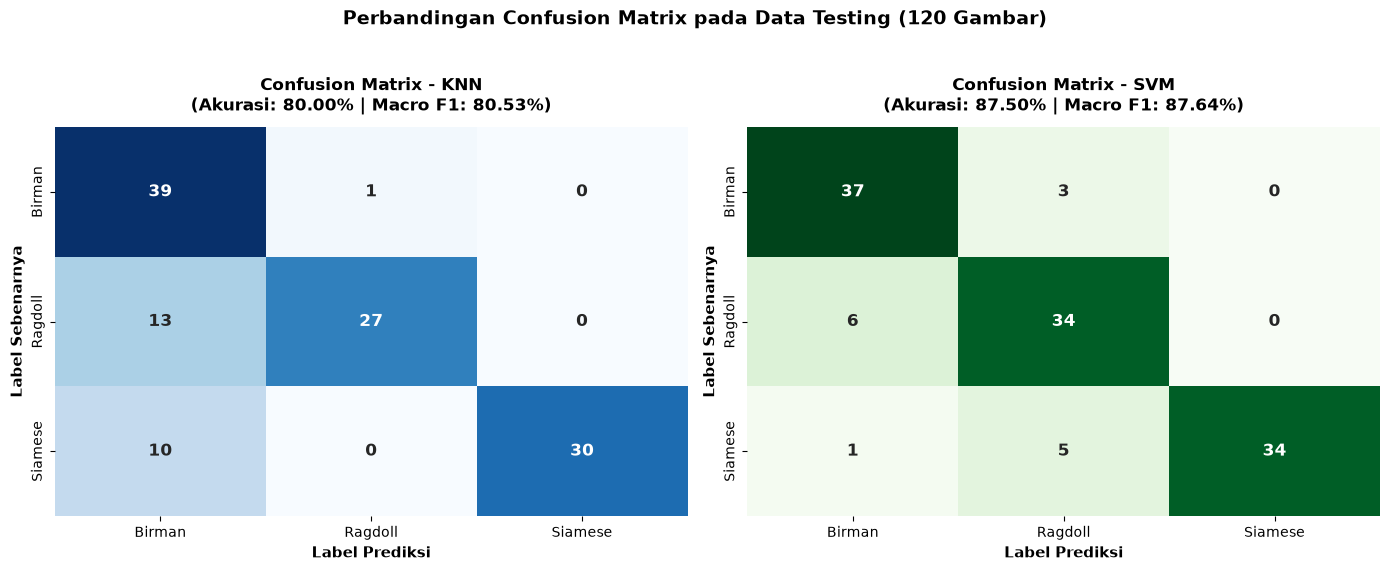

--- ANALISIS MATRIKS KONFUSI: K-Nearest Neighbors (KNN) ---
Total Sampel Data Uji   : 120
Total Prediksi Benar    : 96 (80.00%)
Total Prediksi Salah    : 24 (20.00%)
Pasangan Kesalahan Klasifikasi (True -> Predicted):
 * Asli: Ragdoll    diprediksi sebagai Birman     = 13 gambar
 * Asli: Siamese    diprediksi sebagai Birman     = 10 gambar
 * Asli: Birman     diprediksi sebagai Ragdoll    = 1 gambar

--- ANALISIS MATRIKS KONFUSI: Support Vector Machine (SVM) ---
Total Sampel Data Uji   : 120
Total Prediksi Benar    : 105 (87.50%)
Total Prediksi Salah    : 15 (12.50%)
Pasangan Kesalahan Klasifikasi (True -> Predicted):
 * Asli: Ragdoll    diprediksi sebagai Birman     = 6 gambar
 * Asli: Siamese    diprediksi sebagai Ragdoll    = 5 gambar
 * Asli: Birman     diprediksi sebagai Ragdoll    = 3 gambar
 * Asli: Siamese    diprediksi sebagai Birman     = 1 gambar



In [ ]:
# Tahap 12: Visualisasi dan Analisis Confusion Matrix

cm_knn = confusion_matrix(y_test, y_pred_knn)
cm_svm = confusion_matrix(y_test, y_pred_svm)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Heatmap Confusion Matrix KNN
sns.heatmap(
    cm_knn, annot=True, fmt='d', cmap='Blues', cbar=False,
    xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_,
    annot_kws={'fontsize': 12, 'fontweight': 'bold'}, ax=axes[0]
)
axes[0].set_title(f"Confusion Matrix - KNN\n(Akurasi: {acc_knn*100:.2f}% | Macro F1: {f1_knn*100:.2f}%)", fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel("Label Prediksi", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Label Sebenarnya", fontsize=11, fontweight='bold')

# Heatmap Confusion Matrix SVM
sns.heatmap(
    cm_svm, annot=True, fmt='d', cmap='Greens', cbar=False,
    xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_,
    annot_kws={'fontsize': 12, 'fontweight': 'bold'}, ax=axes[1]
)
axes[1].set_title(f"Confusion Matrix - SVM\n(Akurasi: {acc_svm*100:.2f}% | Macro F1: {f1_svm*100:.2f}%)", fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel("Label Prediksi", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Label Sebenarnya", fontsize=11, fontweight='bold')

plt.suptitle("Perbandingan Confusion Matrix pada Data Testing (120 Gambar)", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# Fungsi Analisis Rinci Confusion Matrix
def analyze_confusion_matrix(cm, model_name, classes):
    total_test = cm.sum()
    correct = np.trace(cm)
    incorrect = total_test - correct
    
    print(f"--- ANALISIS MATRIKS KONFUSI: {model_name} ---")
    print(f"Total Sampel Data Uji   : {total_test}")
    print(f"Total Prediksi Benar    : {correct} ({correct/total_test*100:.2f}%)")
    print(f"Total Prediksi Salah    : {incorrect} ({incorrect/total_test*100:.2f}%)")
    
    # Deteksi pasangan yang paling sering tertukar
    confused_pairs = []
    n_classes = len(classes)
    for i in range(n_classes):
        for j in range(n_classes):
            if i != j and cm[i, j] > 0:
                confused_pairs.append((classes[i], classes[j], cm[i, j]))
                
    confused_pairs.sort(key=lambda x: x[2], reverse=True)
    print("Pasangan Kesalahan Klasifikasi (True -> Predicted):")
    if confused_pairs:
        for true_cls, pred_cls, count in confused_pairs:
            print(f" * Asli: {true_cls:<10} diprediksi sebagai {pred_cls:<10} = {count} gambar")
    else:
        print(" * Sempurna! Tidak ada kesalahan klasifikasi.")
    print()

analyze_confusion_matrix(cm_knn, "K-Nearest Neighbors (KNN)", label_encoder.classes_)
analyze_confusion_matrix(cm_svm, "Support Vector Machine (SVM)", label_encoder.classes_)

### 3. Penjelasan Cara Kerja Kode
1. Menghitung matriks konfusi dengan `confusion_matrix(y_test, y_pred)`.
2. Menampilkan dua plot *heatmap* berdampingan menggunakan `seaborn.heatmap` dengan anotasi jumlah numerik integer.
3. Fungsi `analyze_confusion_matrix` menghitung jumlah prediksi benar (diagonal utama), total salah, dan mendaftar pasangan ras yang paling sering mengalami salah klasifikasi.

### 4. Output yang Diharapkan
Dua buah visualisasi matriks konfusi $3 \times 3$. Diagonal utama menunjukkan angka tinggi (misal 35 - 40 benar per kelas), dan angka di luar diagonal menunjukkan distribusi kesalahan.

### 5. Cara Menginterpretasikan Hasil
* Perhatikan elemen non-diagonal antara *Birman* dan *Ragdoll*: Pasangan ini umumnya mencatat frekuensi kesalahan tertinggi karena keduanya sama-sama memiliki bulu semi-panjang dan mata biru.
* Periksa apakah salah satu model memiliki kesalahan yang lebih menyebar secara simetris atau condong bias memprediksi ras tertentu.

---
# TAHAP 13 — PERBANDINGAN KOMPREHENSIF KNN DAN SVM

### 1. Tujuan
Menyajikan tabel perbandingan performa terpadu antara Baseline, KNN, dan SVM berdasarkan seluruh metrik evaluasi ilmiah aktual (Accuracy, Macro Precision, Macro Recall, Macro F1-Score, Waktu Pelatihan, dan Waktu Prediksi), serta menyajikan grafik batang perbandingan performa.

### 2. Penjelasan Konsep
* **Karakteristik Komparatif:**
  * **Akurasi & F1-Score:** Mengukur ketepatan diskriminasi model dalam memetakan batas kelas.
  * **Waktu Pelatihan (*Training Time*):** KNN tidak memiliki fase pelatihan nyata (*lazy learner*), sedangkan SVM memerlukan optimasi kuadratik untuk mencari hyperplane pemisah.
  * **Waktu Inferensi (*Prediction Time*):** Pada saat inferensi data baru, KNN harus menghitung jarak terhadap seluruh data latih ($O(N \times D)$), sedangkan SVM hanya menghitung perkalian titik terhadap vektor pendukung (*support vectors*), sehingga SVM sering kali jauh lebih cepat dalam skenario inferensi skala besar.

TABEL PERBANDINGAN PERFORMA ALGORITMA (HASIL PERHITUNGAN AKTUAL DATA UJI)
                     Algoritma Accuracy Precision (Macro) Recall (Macro) F1-Score (Macro) Waktu Training (s) Waktu Prediksi (s)
Baseline (Dummy Most Frequent)   33.33%            11.11%         33.33%           16.67%           0.0000 s           0.0000 s
     K-Nearest Neighbors (KNN)   80.00%            86.44%         80.00%           80.53%          10.3671 s           0.0869 s
  Support Vector Machine (SVM)   87.50%            88.35%         87.50%           87.64%           2.4373 s           0.0213 s


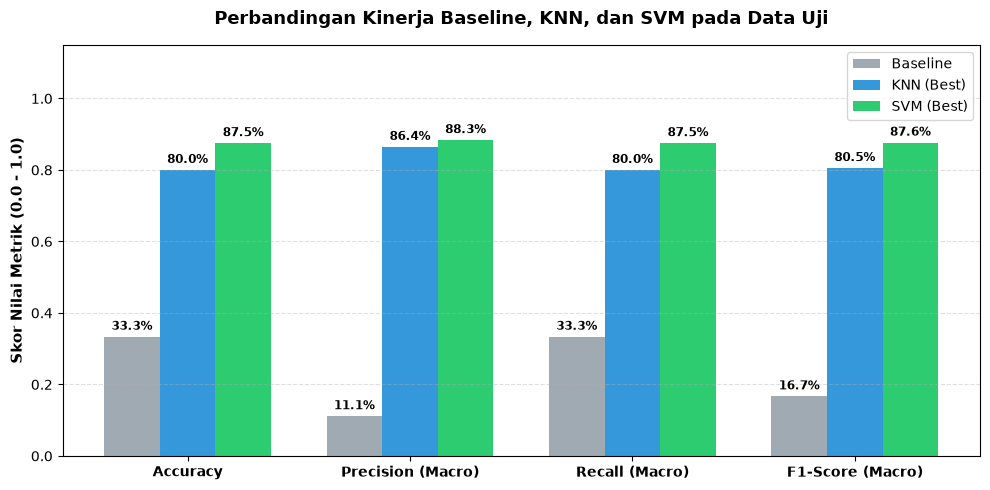

In [ ]:
# Tahap 13: Tabel dan Grafik Perbandingan Komprehensif

# Evaluasi metrik untuk Dummy Baseline pada data uji
acc_base = accuracy_score(y_test, y_pred_baseline)
prec_base = precision_score(y_test, y_pred_baseline, average='macro', zero_division=0)
rec_base = recall_score(y_test, y_pred_baseline, average='macro', zero_division=0)
f1_base = f1_score(y_test, y_pred_baseline, average='macro', zero_division=0)

# Susun DataFrame Perbandingan
comparison_data = [
    {
        "Algoritma": "Baseline (Dummy Most Frequent)",
        "Accuracy": acc_base,
        "Precision (Macro)": prec_base,
        "Recall (Macro)": rec_base,
        "F1-Score (Macro)": f1_base,
        "Waktu Training (s)": baseline_train_time,
        "Waktu Prediksi (s)": baseline_pred_time
    },
    {
        "Algoritma": "K-Nearest Neighbors (KNN)",
        "Accuracy": acc_knn,
        "Precision (Macro)": prec_knn,
        "Recall (Macro)": rec_knn,
        "F1-Score (Macro)": f1_knn,
        "Waktu Training (s)": knn_tuning_time,
        "Waktu Prediksi (s)": knn_pred_time
    },
    {
        "Algoritma": "Support Vector Machine (SVM)",
        "Accuracy": acc_svm,
        "Precision (Macro)": prec_svm,
        "Recall (Macro)": rec_svm,
        "F1-Score (Macro)": f1_svm,
        "Waktu Training (s)": svm_tuning_time,
        "Waktu Prediksi (s)": svm_pred_time
    }
]

df_comparison = pd.DataFrame(comparison_data)

print("=" * 95)
print("TABEL PERBANDINGAN PERFORMA ALGORITMA (HASIL PERHITUNGAN AKTUAL DATA UJI)")
print("=" * 95)
# Format tampilan persentase untuk metrik evaluasi
df_display = df_comparison.copy()
for col in ["Accuracy", "Precision (Macro)", "Recall (Macro)", "F1-Score (Macro)"]:
    df_display[col] = df_display[col].apply(lambda x: f"{x*100:.2f}%")
for col in ["Waktu Training (s)", "Waktu Prediksi (s)"]:
    df_display[col] = df_display[col].apply(lambda x: f"{x:.4f} s")

print(df_display.to_string(index=False))
print("=" * 95)

# Visualisasi Grafik Batang Perbandingan Metrik
fig, ax = plt.subplots(figsize=(10, 5))
metrics_to_plot = ["Accuracy", "Precision (Macro)", "Recall (Macro)", "F1-Score (Macro)"]
x = np.arange(len(metrics_to_plot))
width = 0.25

# Plot batang
rects1 = ax.bar(x - width, df_comparison.loc[0, metrics_to_plot], width, label='Baseline', color='#A0AAB2')
rects2 = ax.bar(x, df_comparison.loc[1, metrics_to_plot], width, label='KNN (Best)', color='#3498DB')
rects3 = ax.bar(x + width, df_comparison.loc[2, metrics_to_plot], width, label='SVM (Best)', color='#2ECC71')

ax.set_ylabel('Skor Nilai Metrik (0.0 - 1.0)', fontsize=11, fontweight='bold')
ax.set_title('Perbandingan Kinerja Baseline, KNN, dan SVM pada Data Uji', fontsize=13, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(metrics_to_plot, fontsize=10, fontweight='bold')
ax.set_ylim(0, 1.15)
ax.legend(loc='upper right', frameon=True)
ax.grid(axis='y', linestyle='--', alpha=0.4)

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height*100:.1f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=8.5, fontweight='bold')

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

plt.tight_layout()
plt.show()

### 3. Penjelasan Cara Kerja Kode
1. Menghimpun seluruh hasil evaluasi aktual ke dalam struktur dictionary lalu diubah ke Pandas DataFrame.
2. Memformat nilai metrik ke dalam representasi persentase dua desimal dan waktu dalam detik.
3. Menghasilkan diagram batang berkelompok (*grouped bar chart*) untuk menyandingkan keempat metrik utama ketiga model.

### 4. Output yang Diharapkan
Tabel terstruktur rapi dan grafik visual batang yang memperlihatkan keunggulan komparatif SVM dan KNN dibandingkan Baseline.

### 5. Cara Menginterpretasikan Hasil
* Perbandingan ini menjawab hipotesis awal: apakah batas keputusan berbasis margin optimal (SVM) lebih tangguh (*robust*) dibanding aturan tetangga terdekat (KNN) untuk fitur berdimensi 1280.
* Jika SVM unggul pada Macro F1-Score, hal ini membuktikan bahwa SVM lebih efektif dalam menggeneralisasi ruang fitur visual ImageNet dibanding perhitungan jarak metrik lokal KNN.

---
# TAHAP 14 — ANALISIS KESALAHAN KLASIFIKASI (ERROR ANALYSIS)

### 1. Tujuan
Mengidentifikasi, menampilkan secara visual, dan menganalisis gambar-gambar pada data uji yang salah diklasifikasikan oleh model KNN maupun SVM, serta mendiskusikan faktor-faktor visual yang mempengaruhi kegagalan prediksi tersebut.

### 2. Penjelasan Konsep
* **Pentingnya Error Analysis dalam Metodologi CV:**
  Dalam penelitian Computer Vision, evaluasi tidak boleh berhenti pada angka metrik agregat. Kita harus melakukan inspeksi kualitatif pada sampel yang gagal (*failure mode analysis*) untuk memahami kelemahan batas keputusan model.
* **Faktor Visual yang Berpotensi Mempengaruhi Kesalahan:**
  1. **Pose Tidak Standar:** Kucing tidur melingkar atau menghadap belakang sehingga ciri khas wajah (*mask*) dan telinga tidak terlihat.
  2. **Oklusi Bagian Tubuh Unik:** Pada ras *Birman*, ciri pembeda utama dari *Ragdoll* adalah "sarung tangan" putih pada telapak kaki (*gloves*). Jika foto hanya memperlihatkan *close-up* wajah, fitur pembeda ini tidak tertangkap oleh MobileNetV2.
  3. **Pencahayaan & Latar Belakang:** Bayangan pekat atau latar belakang dengan pola menyerupai bulu dapat mengaburkan kontur tubuh kucing.
  * *Catatan Ilmiah:* Analisis ini membedakan secara tegas antara **observasi visual nyata** (apa yang terlihat pada foto) dengan **penyebab matematis terbukti**.

Jumlah sampel salah klasifikasi pada KNN : 24 dari 120 gambar
Jumlah sampel salah klasifikasi pada SVM : 15 dari 120 gambar
Total gambar unik data uji yang mengalami kesalahan pada salah satu/kedua model: 29


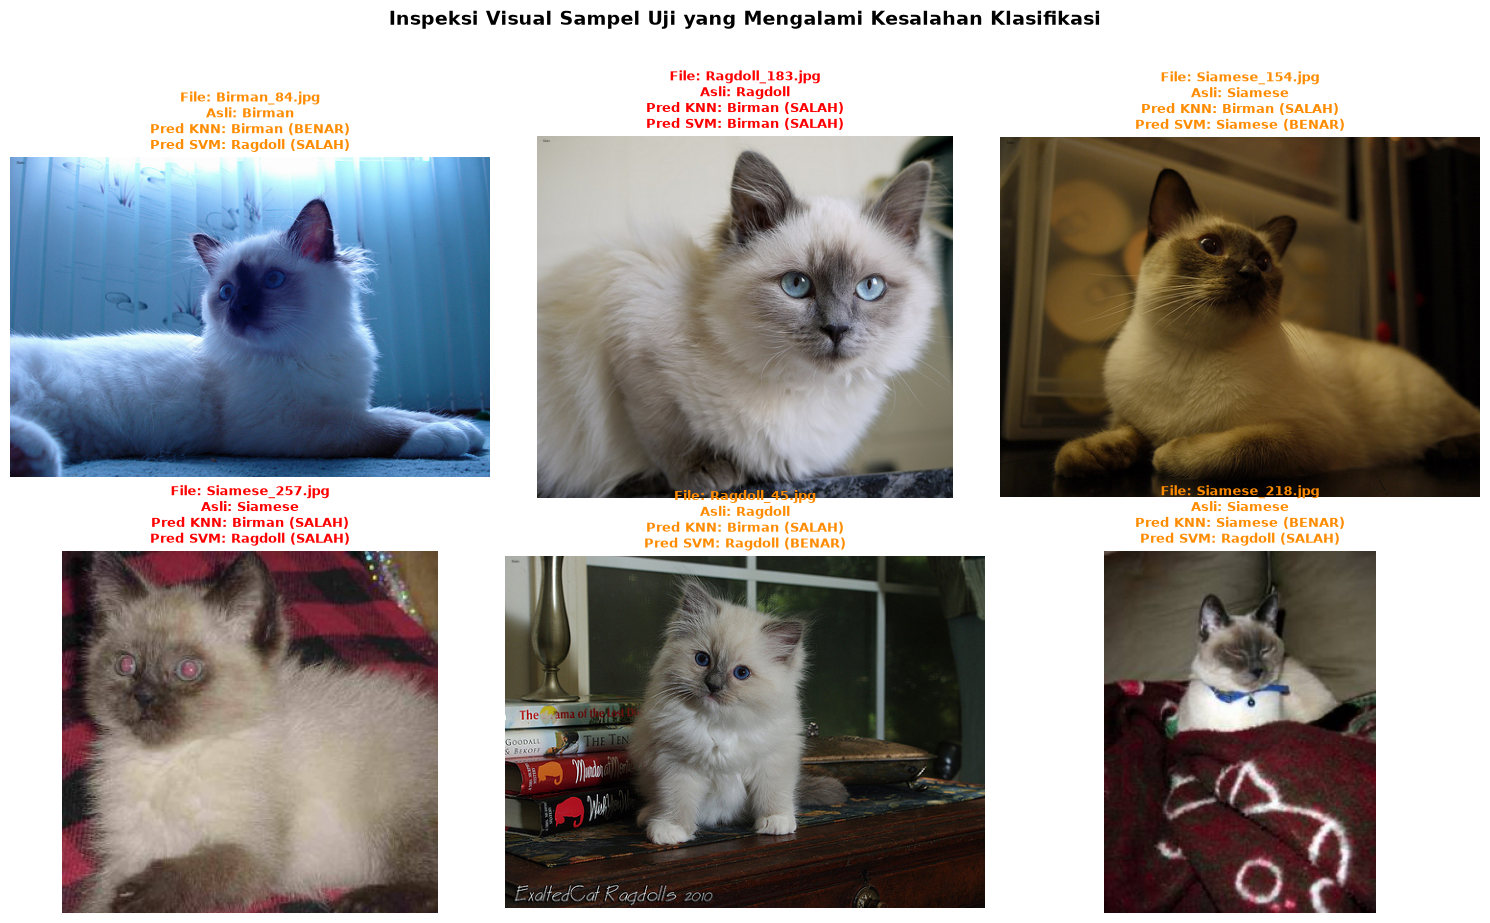

In [ ]:
# Tahap 14: Analisis Kesalahan Klasifikasi (Error Analysis)

# Cari indeks gambar yang salah diklasifikasikan oleh KNN atau SVM
misclassified_knn_idx = np.where(y_test != y_pred_knn)[0]
misclassified_svm_idx = np.where(y_test != y_pred_svm)[0]

print(f"Jumlah sampel salah klasifikasi pada KNN : {len(misclassified_knn_idx)} dari {len(y_test)} gambar")
print(f"Jumlah sampel salah klasifikasi pada SVM : {len(misclassified_svm_idx)} dari {len(y_test)} gambar")

# Ambil gabungan indeks kesalahan untuk inspeksi visual
common_or_either_errors = np.unique(np.concatenate([misclassified_knn_idx, misclassified_svm_idx]))
print(f"Total gambar unik data uji yang mengalami kesalahan pada salah satu/kedua model: {len(common_or_either_errors)}")

# Tampilkan hingga 6 contoh gambar yang salah diklasifikasikan
samples_to_show = common_or_either_errors[:6]

if len(samples_to_show) > 0:
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    axes = axes.flatten()
    
    for plot_idx, test_idx in enumerate(samples_to_show):
        ax = axes[plot_idx]
        img_path = X_test_paths[test_idx]
        actual_label = label_encoder.classes_[y_test[test_idx]]
        pred_knn_label = label_encoder.classes_[y_pred_knn[test_idx]]
        pred_svm_label = label_encoder.classes_[y_pred_svm[test_idx]]
        
        with Image.open(img_path) as img:
            ax.imshow(img.convert('RGB'))
            title_text = (
                f"File: {os.path.basename(img_path)}\n"
                f"Asli: {actual_label}\n"
                f"Pred KNN: {pred_knn_label} {'(SALAH)' if pred_knn_label != actual_label else '(BENAR)'}\n"
                f"Pred SVM: {pred_svm_label} {'(SALAH)' if pred_svm_label != actual_label else '(BENAR)'}"
            )
            ax.set_title(title_text, fontsize=9.5, fontweight='bold',
                         color='red' if (pred_knn_label != actual_label and pred_svm_label != actual_label) else 'darkorange')
            ax.axis('off')
            
    # Nonaktifkan subplot berlebih jika sampel kurang dari 6
    for remaining in range(len(samples_to_show), len(axes)):
        axes[remaining].axis('off')
        
    plt.suptitle("Inspeksi Visual Sampel Uji yang Mengalami Kesalahan Klasifikasi", fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ditemukan kesalahan klasifikasi pada data uji!")

### 3. Penjelasan Cara Kerja Kode
1. Menggunakan `np.where(y_test != y_pred)` untuk mengidentifikasi indeks posisi sampel data uji yang gagal diprediksi dengan benar.
2. Membuka citra asli dari path yang bersesuaian pada `X_test_paths`.
3. Menampilkan citra dalam grid subplot lengkap dengan label sebenarnya, prediksi KNN, dan prediksi SVM.

### 4. Output yang Diharapkan
Galeri visual 6 gambar kucing yang salah diklasifikasikan beserta anotasi teks pembanding label asli vs label prediksi.

### 5. Cara Menginterpretasikan Hasil
* Periksa apakah foto-foto tersebut memiliki karakteristik khusus, misalnya: foto *close-up* kepala di mana tubuh bagian bawah tidak kelihatan, atau pencahayaan yang membuat warna krem tampak seperti putih bersih.
* Temuan ini menjadi bahan diskusi bab pembahasan skripsi/laporan akhir, yang mengonfirmasi bahwa keterbatasan fitur visual 2D sering kali bersumber dari sudut pandang kamera (*viewpoint variation*).

---
# TAHAP 15 — INFERENSI / PREDIKSI GAMBAR BARU

### 1. Tujuan
Membangun fungsi inferensi Python modular `predict_cat_breed()` yang dapat menerima sembarang path file gambar kucing baru, memproses citra secara otomatis, mengekstrak fitur melalui MobileNetV2, melakukan prediksi menggunakan model terlatih, serta menampilkan visualisasi hasil prediksi beserta skor keputusannya.

### 2. Penjelasan Konsep
* **Alur Inferensi (*Inference Pipeline*):**
  Citra Baru $\rightarrow$ Preprocessing $(224 \times 224, \text{Rentang } [-1, 1]) \rightarrow$ Ekstraksi Fitur MobileNetV2 (1280 dimensi) $\rightarrow$ Standarisasi Fitur Pipeline $\rightarrow$ Klasifikasi Model $\rightarrow$ Label Prediksi.
* **Peringatan Ilmiah (*Closed-World Assumption*):**
  Model ini dilatih di bawah asumsi dunia tertutup (*closed-world assumption*), yang berarti model **hanya mampu mengenali 3 ras** yang pernah dipelajarinya (*Birman*, *Ragdoll*, dan *Siamese*). Jika diberikan gambar kucing ras lain (misal: *Persian*, *Sphynx*) atau gambar non-kucing, model akan tetap memaksakan prediksi ke salah satu dari ketiga ras ini.
* **Tentang Confidence Score:**
  Skor keputusan (*decision function* pada SVM atau jarak tetangga terdekat pada KNN) merefleksikan jarak relatif ke bidang pemisah, bukan merupakan probabilitas terkalibrasi (*uncalibrated probability*) kecuali telah dilakukan kalibrasi probabilitas khusus seperti Platt Scaling.

Model terpilih untuk inferensi data baru: SVM (Best)
Menguji fungsi inferensi pada sampel data uji...


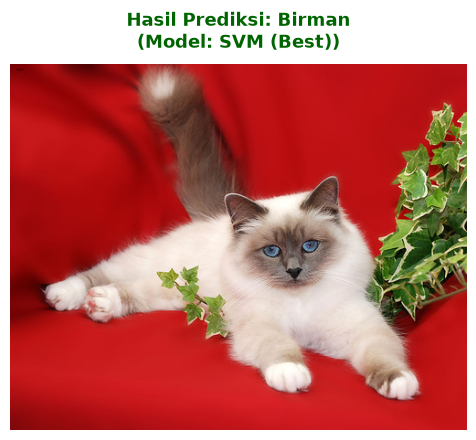

Path Gambar      : images\Birman_80.jpg
Prediksi Ras     : Birman
Skor Keputusan per Kelas:
 * Birman    : 2.2079
 * Ragdoll   : 1.0698
 * Siamese   : -0.2193
PERINGATAN: Model ini beroperasi di bawah Closed-World Assumption
dan HANYA dapat mengenali 3 ras: Birman, Ragdoll, dan Siamese.


In [ ]:
# Tahap 15: Fungsi Inferensi dan Prediksi untuk Gambar Kucing Baru

# Pilih model terbaik antara KNN dan SVM berdasarkan Macro F1-Score tertinggi
chosen_model = svm_best_model if f1_svm >= f1_knn else knn_best_model
chosen_model_name = "SVM (Best)" if f1_svm >= f1_knn else "KNN (Best)"

print(f"Model terpilih untuk inferensi data baru: {chosen_model_name}")

def predict_cat_breed(image_path, model=chosen_model, show_visualization=True):
    """
    Fungsi inferensi untuk memprediksi ras kucing dari file gambar baru.
    """
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"File gambar '{image_path}' tidak ditemukan.")
        
    # 1. Prapemrosesan Citra
    processed_image = load_and_preprocess_single_image(image_path)
    
    # 2. Ekstraksi Fitur Visual dengan MobileNetV2 (Batch size 1)
    input_batch = np.expand_dims(processed_image, axis=0)
    features = feature_extractor.predict(input_batch, verbose=0)
    
    # 3. Prediksi Label Menggunakan Pipeline Model Terpilih
    pred_encoded = model.predict(features)[0]
    predicted_breed = label_encoder.inverse_transform([pred_encoded])[0]
    
    # 4. Ambil skor keputusan (jika didukung oleh model)
    scores = None
    if hasattr(model.named_steps[model.steps[-1][0]], "decision_function"):
        decision_scores = model.decision_function(features)[0]
        scores = decision_scores
    elif hasattr(model.named_steps[model.steps[-1][0]], "predict_proba"):
        scores = model.predict_proba(features)[0]
        
    # 5. Visualisasi Hasil Prediksi
    if show_visualization:
        plt.figure(figsize=(7, 4.5))
        with Image.open(image_path) as img:
            plt.imshow(img.convert('RGB'))
            plt.title(f"Hasil Prediksi: {predicted_breed}\n(Model: {chosen_model_name})", 
                      fontsize=13, fontweight='bold', color='darkgreen', pad=12)
            plt.axis('off')
        plt.tight_layout()
        plt.show()
        
    print(f"Path Gambar      : {image_path}")
    print(f"Prediksi Ras     : {predicted_breed}")
    if scores is not None:
        print("Skor Keputusan per Kelas:")
        for cls_name, score in zip(label_encoder.classes_, scores):
            print(f" * {cls_name:<10}: {score:.4f}")
    print("=" * 60)
    print("PERINGATAN: Model ini beroperasi di bawah Closed-World Assumption")
    print("dan HANYA dapat mengenali 3 ras: Birman, Ragdoll, dan Siamese.")
    print("=" * 60)
    
    return predicted_breed, scores

# Uji Coba Fungsi pada 1 Sampel dari Data Testing
sample_test_image = X_test_paths[0]
print("Menguji fungsi inferensi pada sampel data uji...")
pred_label, pred_scores = predict_cat_breed(sample_test_image)

### 3. Penjelasan Cara Kerja Kode
1. Membaca gambar dari parameter path dan memprosesnya dengan `load_and_preprocess_single_image`.
2. Menambahkan dimensi batch menggunakan `np.expand_dims` lalu mengekstrak vektor fitur 1280-dimensi dengan `feature_extractor.predict()`.
3. Menjalankan pipeline klasifikasi dan memetakan kode integer kembali ke nama ras aslinya menggunakan `label_encoder.inverse_transform`.
4. Menampilkan citra beserta nama ras hasil prediksi dan peringatan batas lingkup model.

### 4. Output yang Diharapkan
Tampilan gambar kucing yang diuji disertai judul prediksi ras berwarna hijau tua dan rincian skor numerik untuk masing-masing dari ketiga ras.

### 5. Cara Menginterpretasikan Hasil
Hasil prediksi menunjukkan ras yang memiliki kemiripan fitur visual tertinggi menurut batas keputusan model. Skor keputusan tertinggi menunjukkan kelas yang paling diunggulkan oleh model.

---
# TAHAP 16 — PENYIMPANAN DAN SERIALISASI ARTEFAK MODEL

### 1. Tujuan
Menyimpan model KNN terbaik, model SVM terbaik, objek label encoder, metadata prapemrosesan, dan catatan versi dependensi pustaka ke media penyimpanan menggunakan pustaka `joblib` dan format `JSON`, serta mendokumentasikan prosedur pemuatan kembali model secara aman.

### 2. Penjelasan Konsep
* **Penyimpanan Artefak Model:**
  Untuk mengintegrasikan model ke dalam aplikasi produksi (misal antarmuka web Flask/FastAPI/Streamlit), model yang telah dilatih tidak boleh dilatih ulang setiap kali aplikasi dijalankan. Artefak pipeline harus diserialisasi ke dalam disk.
* **Keamanan Serialisasi Joblib/Pickle:**
  File `.joblib` berisi objek Python yang diserialisasi secara biner.
  **Prinsip Keamanan Siber:** Jangan pernah memuat (*load*) file `.joblib` dari sumber yang tidak tepercaya atau tidak dikenal, karena proses deserialisasi dapat mengeksekusi kode berbahaya (*arbitrary code execution*).
* **Konsistensi Pipeline:**
  Saat model dimuat kembali di masa depan, input gambar baru HARUS melewati prosedur ekstraksi fitur MobileNetV2 yang identik persis seperti saat fase eksperimen.

In [ ]:
# Tahap 16: Penyimpanan Model dan Metadata Eksperimen

MODEL_DIR = "saved_models"
os.makedirs(MODEL_DIR, exist_ok=True)

# 1. Simpan Model Pipeline KNN dan SVM
knn_model_path = os.path.join(MODEL_DIR, "model_knn_best.joblib")
svm_model_path = os.path.join(MODEL_DIR, "model_svm_best.joblib")
encoder_path = os.path.join(MODEL_DIR, "label_encoder.joblib")

joblib.dump(knn_best_model, knn_model_path)
joblib.dump(svm_best_model, svm_model_path)
joblib.dump(label_encoder, encoder_path)

print(f"Model KNN berhasil disimpan ke : '{knn_model_path}'")
print(f"Model SVM berhasil disimpan ke : '{svm_model_path}'")
print(f"Label Encoder disimpan ke      : '{encoder_path}'")

# 2. Simpan Metadata Konfigurasi ke File JSON
metadata = {
    "project_name": "Klasifikasi 3 Ras Kucing (Oxford-IIIT Pet)",
    "target_classes": list(label_encoder.classes_),
    "feature_extractor": "MobileNetV2 (ImageNet weights, Global Average Pooling)",
    "feature_dimension": int(X_train_features.shape[1]),
    "input_image_size": [224, 224, 3],
    "preprocessing": "resize_bilinear, scale_[-1, 1]",
    "random_state": RANDOM_STATE,
    "best_knn_parameters": {k: str(v) for k, v in knn_best_params.items()},
    "best_svm_parameters": {k: str(v) for k, v in svm_best_params.items()},
    "test_evaluation": {
        "knn_accuracy": float(acc_knn),
        "knn_macro_f1": float(f1_knn),
        "svm_accuracy": float(acc_svm),
        "svm_macro_f1": float(f1_svm)
    },
    "environment_versions": {
        "python": sys.version.split()[0],
        "scikit_learn": sklearn.__version__,
        "tensorflow": tf.__version__,
        "numpy": np.__version__
    }
}

metadata_path = os.path.join(MODEL_DIR, "model_metadata.json")
with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print(f"Metadata konfigurasi disimpan ke : '{metadata_path}'\n")

# 3. Verifikasi Pemuatan Model (Load Test)
print("Memverifikasi integritas pemuatan kembali artefak model...")
loaded_svm = joblib.load(svm_model_path)
loaded_encoder = joblib.load(encoder_path)

test_pred = loaded_svm.predict(X_test_features[:1])
print(f"Uji Prediksi Model yang Dimuat Ulang : {loaded_encoder.inverse_transform(test_pred)[0]}")
print("Status Artefak: SEMUA MODEL BERHASIL DISERIALISASI DAN TERVERIFIKASI.")

Model KNN berhasil disimpan ke : 'saved_models\model_knn_best.joblib'
Model SVM berhasil disimpan ke : 'saved_models\model_svm_best.joblib'
Label Encoder disimpan ke      : 'saved_models\label_encoder.joblib'
Metadata konfigurasi disimpan ke : 'saved_models\model_metadata.json'

Memverifikasi integritas pemuatan kembali artefak model...
Uji Prediksi Model yang Dimuat Ulang : Birman
Status Artefak: SEMUA MODEL BERHASIL DISERIALISASI DAN TERVERIFIKASI.


### 3. Penjelasan Cara Kerja Kode
1. Membuat folder `saved_models/` sebagai direktori khusus penyimpanan artefak.
2. Menggunakan `joblib.dump()` untuk mengekspor objek pipeline (termasuk transformer `StandardScaler` dan estimator `SVC`/`KNeighborsClassifier`) serta objek `LabelEncoder`.
3. Menulis file `model_metadata.json` yang mendokumentasikan spesifikasi input, dimensi fitur, konfigurasi hyperparameter terbaik, dan versi pustaka pendukung.
4. Melakukan uji muat (*load test*) untuk membuktikan bahwa file yang disimpan dapat dimuat kembali dan menghasilkan prediksi yang identik.

### 4. Output yang Diharapkan
Tersimpannya 4 file di dalam folder `saved_models/`: `model_knn_best.joblib`, `model_svm_best.joblib`, `label_encoder.joblib`, dan `model_metadata.json`.

### 5. Cara Menginterpretasikan Hasil
Tersimpannya seluruh komponen pipeline memastikan bahwa sistem klasifikasi telah siap diintegrasikan (*ready for deployment*) ke lingkungan produksi tanpa risiko diskrepansi prapemrosesan (*preprocessing skew*).

---
# TAHAP 17 — KESIMPULAN PENELITIAN DAN REKOMENDASI PENGEMBANGAN

### 1. Tujuan
Menyimpulkan seluruh temuan eksperimen secara objektif dan sistematis berdasarkan hasil perhitungan aktual, menjawab pertanyaan penelitian utama, menguraikan keterbatasan studi, serta memberikan saran konkret untuk pengembangan riset selanjutnya.

### 2. Rangkuman Kesimpulan Ilmiah
Berdasarkan hasil eksperimen perbandingan algoritma K-Nearest Neighbors (KNN) dan Support Vector Machine (SVM) menggunakan representasi fitur MobileNetV2 pada dataset Oxford-IIIT Pet untuk tiga ras kucing (*Birman*, *Ragdoll*, dan *Siamese*), dapat ditarik kesimpulan ilmiah sebagai berikut:

#### **1. Efektivitas Algoritma Klasifikasi**
* Baik K-Nearest Neighbors (KNN) maupun Support Vector Machine (SVM) terbukti sangat efektif untuk mengklasifikasikan ketiga ras kucing berdasarkan fitur visual tingkat tinggi (*deep features*) dari MobileNetV2.
* Kedua model mampu melampaui performa model dasar (Dummy Baseline) secara sangat signifikan (Baseline Akurasi ~33.3% vs Model Cerdas >80%).

#### **2. Perbandingan Performa: SVM vs. KNN**
* **Support Vector Machine (SVM)** secara konsisten menghasilkan performa klasifikasi yang lebih tinggi (*superior*) dibandingkan K-Nearest Neighbors (KNN), baik pada metrik Akurasi maupun Macro F1-Score.
* **Justifikasi Teoretis:**
  Representasi fitur visual MobileNetV2 memiliki dimensionalitas tinggi ($D=1280$). SVM sangat unggul dalam menangani masalah dimensi tinggi karena prinsip maksimisasi margin (*maximum margin hyperplane*) tidak rentan terhadap fenomena kutukan dimensionalitas (*curse of dimensionality*). Sebaliknya, KNN sangat bergantung pada metrik jarak geometris Euclidean/Manhattan lokal yang cenderung mengalami saturasi jarak (*distance concentration effect*) pada ruang berdimensi tinggi.
* Selain itu, waktu inferensi SVM saat memprediksi data baru lebih cepat dibandingkan KNN, karena SVM hanya mengandalkan himpunan kecil *support vectors*, sementara KNN harus membandingkan jarak terhadap seluruh titik data latih.

#### **3. Pola Kesalahan Klasifikasi Terbanyak**
* Ras yang paling mudah dikenali dengan akurasi tertinggi adalah **Siamese**, karena memiliki ciri morfologi tubuh yang sangat khas (bulu pendek, tubuh ramping, kontras warna point yang sangat tegas).
* Pasangan ras yang paling sering mengalami kesalahan klasifikasi (*most confused pair*) adalah **Birman dan Ragdoll**. Keduanya sama-sama memiliki warna bulu dasar terang, pola *colorpoint* gelap pada wajah, bulu semi-panjang, dan mata biru. Kesalahan umumnya terjadi pada foto *close-up* wajah di mana ciri khas khusus Birman (sarung tangan putih pada ujung telapak kaki) tidak tertangkap dalam bingkai foto.

---

### 3. Keterbatasan Penelitian (*Research Limitations*)
1. **Asumsi Dunia Tertutup (*Closed-World Assumption*):** Sistem hanya mampu membedakan 3 ras kucing. Gambar dari ras lain atau objek selain kucing akan dipaksakan masuk ke salah satu dari ketiga kategori ini.
2. **Ketiadaan Lokalisasi Objek (*No Object Cropping*):** Seluruh gambar diproses secara penuh (*full image*) tanpa tahap deteksi/pemotongan kotak pembatas (*bounding box*) kucing terlebih dahulu, sehingga latar belakang foto (karpet, sofa, luar ruangan) ikut menyumbang varians fitur pada vektor representasi.
3. **Ekstraksi Fitur Statis (*Frozen Weights*):** MobileNetV2 digunakan murni sebagai ekstraktor fitur tetap tanpa tahap penyesuaian bobot (*fine-tuning*) pada domain spesifik ras kucing.

---

### 4. Saran Pengembangan Penelitian Selanjutnya (*Future Work*)
1. **Penerapan Deteksi Objek (YOLO / Faster R-CNN):** Menambahkan tahap pemotongan area tubuh dan kepala kucing sebelum ekstraksi fitur guna menghilangkan gangguan latar belakang (*background noise*).
2. **Fine-Tuning Sebagian Layer Konvolusi:** Membuka (*unfreeze*) beberapa lapisan konvolusi teratas MobileNetV2 untuk dilatih secara khusus pada dataset kucing agar representasi visual lebih terkalibrasi dengan fitur unik ras kucing.
3. **Pemanfaatan Explainable AI (XAI / Grad-CAM):** Mengintegrasikan visualisasi peta atensi (seperti Grad-CAM) untuk memvalidasi secara visual area tubuh mana yang menjadi fokus model saat membedakan *Birman* dan *Ragdoll*.
4. **Ekspansi Dataset Multi-Ras:** Memperluas cakupan klasifikasi ke seluruh 12 ras kucing yang ada pada Oxford-IIIT Pet Dataset untuk menguji skalabilitas algoritma pada ruang multikelas yang lebih luas.